In [57]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.datasets as Datasets
import torchvision.transforms as transforms
from torchvision import datasets
import torch.nn.functional as F
import torchvision.models as models
import torchvision.utils as vutils

import os
import random
import numpy as np
import math
from IPython.display import clear_output
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.notebook import trange, tqdm


GPU_index = 0
device = torch.device(GPU_index if torch.cuda.is_available() else 'cpu')


In [58]:

## 1. Definieer transformaties (zet afbeeldingen om naar PyTorch Tensors en normaliseer ze)
transform = transforms.Compose([
    transforms.Resize(32),
    transforms.ToTensor(),
])

train_transformer = transforms.Compose([
    transforms.Resize(32),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
])

## 2. Download en laad de MNIST training- en testdataset
train_dataset = datasets.MNIST(
    root='./data',
    train=True,
    download=True,
    transform=train_transformer
)

test_dataset = datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

## 3. Maak DataLoaders aan voor batchverwerking
train_loader = DataLoader(train_dataset, batch_size=64,num_workers=0, shuffle=True,pin_memory=True,persistent_workers=False)
test_loader = DataLoader(test_dataset, batch_size=64,num_workers=0, shuffle=False,pin_memory=True,persistent_workers=False)

## 4. Test de DataLoader door één batch op te halen
data_iter = iter(train_loader)
images, labels = next(data_iter)

print("**Vorm van de afbeeldingen batch:**", images.shape)  # Verwacht: [64, 1, 28, 28] (batch, kanalen, hoogte, breedte)
print("**Vorm van de labels batch:**", labels.shape)        # Verwacht: [64]
print("**Labels van de eerste paar afbeeldingen in de batch:**", labels[:10])

**Vorm van de afbeeldingen batch:** torch.Size([64, 1, 32, 32])
**Vorm van de labels batch:** torch.Size([64])
**Labels van de eerste paar afbeeldingen in de batch:** tensor([0, 0, 5, 8, 1, 4, 9, 3, 6, 4])


In [59]:
noise_scale=0.3
def add_noise(images, p=noise_scale):
    flip = torch.bernoulli(p * torch.ones_like(images))
    return (images - flip).abs()

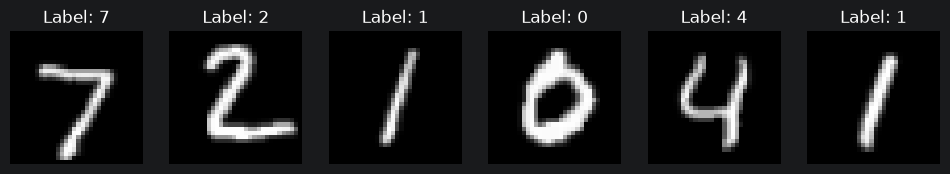

In [60]:
import matplotlib.pyplot as plt

images_test, labels = next(iter(test_loader))

images_6 = images_test[:6]
labels_6 = labels[:6]

fig, axes = plt.subplots(1, 6, figsize=(12, 3))

for i in range(6):
    # .squeeze() verwijdert de kleurkanalendimensie (1) zodat de afbeelding 2D wordt (28x28)
    img = images_6[i].squeeze()

    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(f"Label: {labels_6[i].item()}")
    axes[i].axis('off') # Verberg de as-lijnen voor een schoner uiterlijk

plt.show()


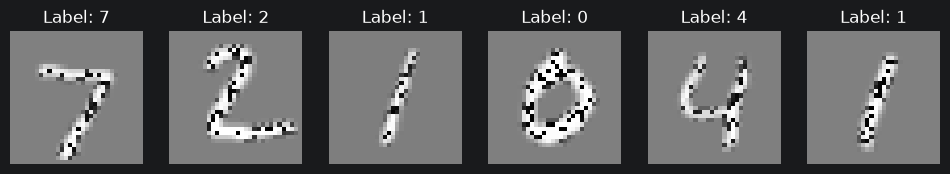

In [61]:
import matplotlib.pyplot as plt
import torch

# 1. Maak een NIEUWE figuur en axes aan voor de tweede plot
fig, axes = plt.subplots(1, 6, figsize=(12, 3))

# 2. Herstelde ruis-code (met de ontbrekende minnetjes toegevoegd)

mask = torch.bernoulli((1 - noise_scale) * torch.ones_like(images_test)) * 2 - 1   # +1 = behouden, -1 = flippen
noisey_img = images_test * mask
# 3. Loop door de nieuwe axes om te plotten
for i in range(6):
    img = noisey_img[i].squeeze()

    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(f"Label: {labels_6[i].item()}")
    axes[i].axis('off')

plt.show()

In [62]:
print(images.shape)

torch.Size([64, 1, 32, 32])


In [63]:
class DownBlock(nn.Module):
    def __init__(self, channels_in, channels_out):
        super().__init__()
        self.skip = nn.Conv2d(channels_in, channels_out, 1, 2)
        self.conv1 = nn.Conv2d(channels_in, channels_in , 3, 1,1)
        self.bn1 = nn.BatchNorm2d(channels_in)

        self.conv2 = nn.Conv2d(channels_in, channels_out, 3,2,1)
        self.bn2 = nn.BatchNorm2d(channels_out)
    def forward(self, x):
        x_skip = self.skip(x)
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.bn2(self.conv2(x))

        return F.relu(x + x_skip)


class UpBlock(nn.Module):
    def __init__(self, channels_in, channels_out):
        super().__init__()
        self.bn1 = nn.BatchNorm2d(channels_in)

        self.conv1 = nn.Conv2d(channels_in, channels_in, 3,1,1)

        self.conv2 = nn.ConvTranspose2d(channels_in, channels_out, 3,2, 1, 1)
        self.bn2 = nn.BatchNorm2d(channels_out)
    def forward(self, x_raw):
        x = F.relu(self.bn1(x_raw))
        x = self.conv1(x) + x_raw

        x = self.conv2(x)
        return x

In [64]:
class Encoder(nn.Module):
    def __init__(self, channels, ch=32, z=32):
        super().__init__()
        self.blok1 = DownBlock(channels, ch )
        self.blok2 = DownBlock(ch, ch*2)
        self.blok3 = DownBlock(ch*2, ch*4)

        self.conv = nn.Conv2d(ch*4, z, 4,1)
    def forward(self, x):
        x = self.blok1(x)
        x = self.blok2(x)
        x = self.blok3(x)
        x = self.conv(x)
        return x

class Decoder(nn.Module):
    def __init__(self, channels, ch=32, z=32):
        super().__init__()
        self.conv = nn.ConvTranspose2d(z, ch*4, 4,1)
        self.blok1 = UpBlock(ch*4, ch*2)
        self.blok2 = UpBlock(ch*2, ch)
        self.blok3 = UpBlock(ch, channels)
    def forward(self, x):
        x = self.conv(x)
        x = self.blok1(x)
        x = self.blok2(x)
        x = self.blok3(x)
        return x

In [65]:
class AE(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.encoder = Encoder(channels=channels)
        self.decoder = Decoder(channels=channels)
    def forward(self, x):
        encoder = self.encoder(x)
        x = self.decoder(encoder)
        return x

In [66]:
LR = 0.5
EPOCHS = 3


In [67]:
myModel = AE(channels=1).to(device)

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(myModel.parameters(), lr=LR)
lr_schedule = torch.optim.lr_scheduler.StepLR(optimizer, 1, 0.1, -1)

loss_log = []
train_acc = []
test_acc = []

In [68]:
LR = 1e-3
optimizer = torch.optim.Adam(myModel.parameters(), lr=LR)
lr_schedule = torch.optim.lr_scheduler.StepLR(optimizer, step_size=1, gamma=0.5)

train_log, val_log = [], []

def training_loop(loader, criterion, optimizer, model, log, device):
    model.train()
    for images, _ in tqdm(loader, leave=False, desc='Train'):
        images = images.to(device)
        preds = model(add_noise(images))
        loss = criterion(preds, images)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        log.append(loss.item())

def evaluation_loop(loader, criterion, model, device):
    model.eval()
    total, n = 0, 0
    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device)
            preds = model(add_noise(images))
            total += criterion(preds, images).item() * images.size(0)
            n += images.size(0)
    return total / n

for epoch in range(EPOCHS):
    training_loop(train_loader, criterion, optimizer, myModel, train_log, device)
    val_log.append(evaluation_loop(test_loader, criterion, myModel, device))
    lr_schedule.step()
    print(f'Epoch {epoch+1}: val loss {val_log[-1]:.4f}')


Train:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 1: val loss 0.1137


Train:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 2: val loss 0.1083


Train:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 3: val loss 0.1065


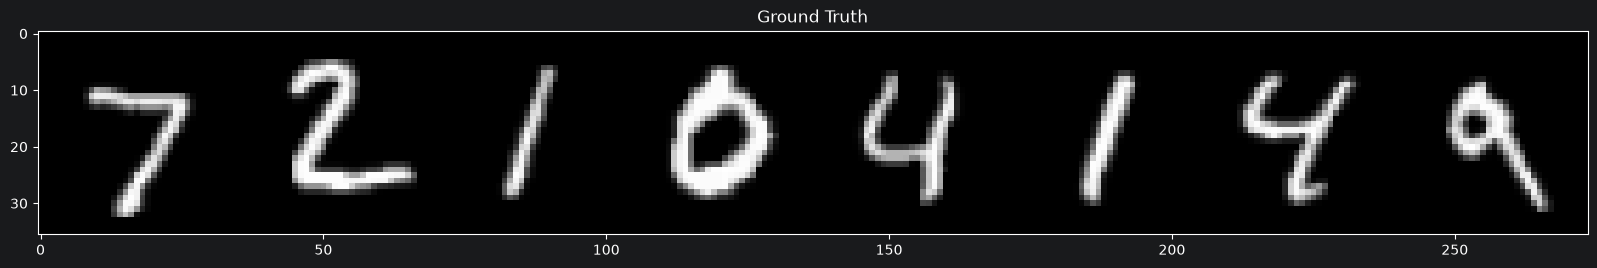

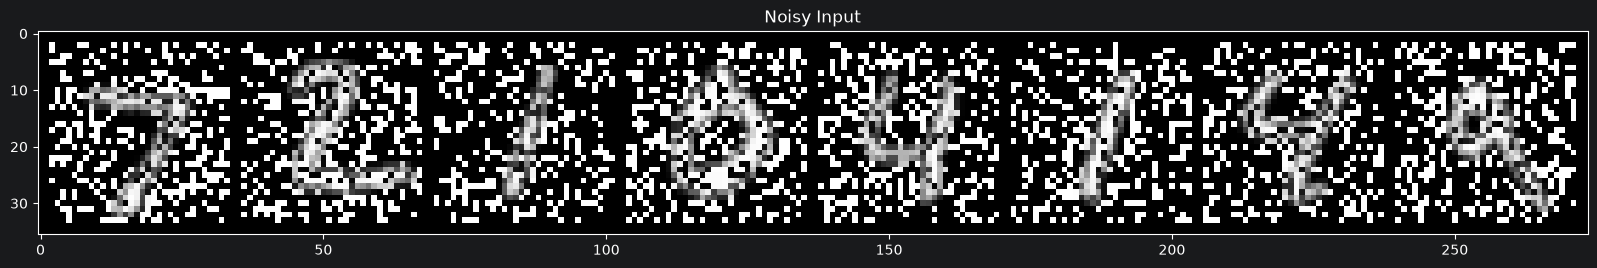

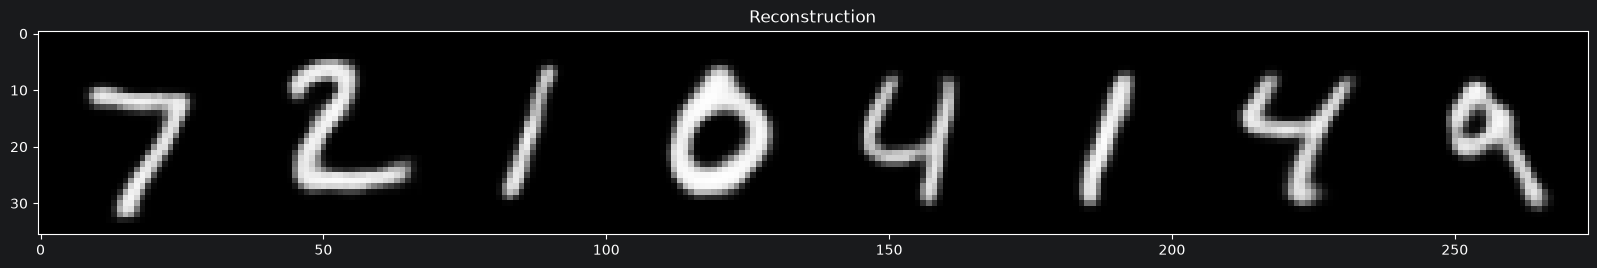

In [69]:
myModel.eval()
images_test, _ = next(iter(test_loader))
flip = torch.bernoulli(noise_scale * torch.ones_like(images_test))
noisey_img = (images_test - flip).abs()

with torch.no_grad():
    recon_data = torch.sigmoid(myModel(noisey_img.to(device))).cpu()

for title, batch in [("Ground Truth", images_test), ("Noisy Input", noisey_img), ("Reconstruction", recon_data)]:
    plt.figure(figsize=(20, 10))
    plt.title(title)
    out = vutils.make_grid(batch[0:8], normalize=True)
    plt.imshow(out.numpy().transpose((1, 2, 0)))

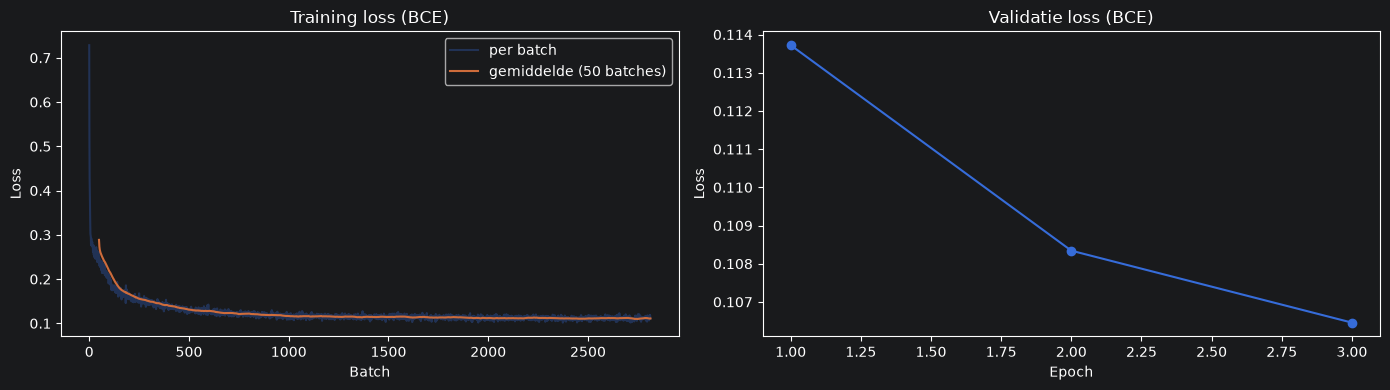

In [71]:
import numpy as np
import matplotlib.pyplot as plt

def smooth(x, k=50):
    return np.convolve(x, np.ones(k) / k, mode='valid')

fig, ax = plt.subplots(1, 2, figsize=(14, 4))

# Training loss per batch (met gemiddelde eroverheen)
ax[0].plot(train_log, alpha=0.3, label='per batch')
ax[0].plot(range(49, len(train_log)), smooth(train_log), label='gemiddelde (50 batches)')
ax[0].set_title('Training loss (BCE)')
ax[0].set_xlabel('Batch')
ax[0].set_ylabel('Loss')
ax[0].legend()

# Validatie loss per epoch
ax[1].plot(range(1, len(val_log) + 1), val_log, marker='o')
ax[1].set_title('Validatie loss (BCE)')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Loss')

plt.tight_layout()
plt.show()